# Assignment II — AIMLZG565 — Machine Learning

**Work Integrated Learning Programmes Division**

**M. Tech. in Artificial Intelligence & Machine Learning**

**I Semester 2026-27**

---

**Assignment II**

**Student Name:** Bhayani Krish Mayurbhai

**BITS ID:** 2026AJ05260

**Semester:** 1st (2026-27)

---

## Bank Marketing Subscription Prediction

### Problem Statement

Predict whether a bank customer will subscribe to a term deposit based on customer demographic information, financial details, and marketing campaign attributes.

The problem is a binary classification task where the target variable represents whether the customer subscribed to the term deposit (Yes/No).

In [1]:
# ============================================================
# 0. Environment Setup
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

%matplotlib inline

sns.set_theme(style="whitegrid")

print("Python environment initialized successfully!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Python environment initialized successfully!
NumPy: 2.4.6
Pandas: 3.0.3
Scikit-learn: 1.9.0


In [2]:
# ============================================================
# 1. Dataset Download and Loading
# ============================================================

import os
import urllib.request
import zipfile
import shutil
from pathlib import Path
import pandas as pd

# Create project directories
BASE_DIR = Path.cwd()

DATASET_DIR = BASE_DIR / "dataset"
MODEL_DIR = BASE_DIR / "models"
OUTPUT_DIR = BASE_DIR / "outputs"

DATASET_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

# Official UCI dataset URL
dataset_url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

zip_path = DATASET_DIR / "bank_marketing.zip"
bank_zip_path = DATASET_DIR / "bank.zip"
csv_path = DATASET_DIR / "bank-full.csv"

# Download dataset
if not zip_path.exists():
    urllib.request.urlretrieve(dataset_url, zip_path)

print("Dataset downloaded successfully!")

# Extract bank.zip from the main ZIP file
with zipfile.ZipFile(zip_path, "r") as zip_ref:

    with zip_ref.open("bank.zip") as source:
        with open(bank_zip_path, "wb") as destination:
            shutil.copyfileobj(source, destination)

print("Bank dataset archive extracted successfully!")

# Extract bank-full.csv from bank.zip
with zipfile.ZipFile(bank_zip_path, "r") as zip_ref:

    csv_file = next(
        file for file in zip_ref.namelist()
        if file.split("/")[-1].lower() == "bank-full.csv"
    )

    with zip_ref.open(csv_file) as source:
        with open(csv_path, "wb") as destination:
            shutil.copyfileobj(source, destination)

print("Dataset extracted successfully!")
print("Dataset location:", csv_path)

# Load dataset
df = pd.read_csv(csv_path, sep=";")

print("\nDataset loaded successfully!")
print("Dataset Shape:", df.shape)

# Display first five records
display(df.head())

Dataset downloaded successfully!
Bank dataset archive extracted successfully!
Dataset extracted successfully!
Dataset location: /Users/LENOVO/Desktop/ML/Assignment 2/dataset/bank-full.csv

Dataset loaded successfully!
Dataset Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


In [4]:
# Display statistical summary of numerical columns
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [5]:
# Count the number of records in each target class
print("Target Variable Distribution:")
print(df["y"].value_counts())

# Display percentage distribution
print("\nTarget Variable Percentage:")
print(df["y"].value_counts(normalize=True) * 100)

Target Variable Distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Target Variable Percentage:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


In [6]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nTotal Duplicate Records:")
print(df.duplicated().sum())

Missing Values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Total Duplicate Records:
0


The Bank Marketing dataset contains 45,211 customer records and 17 columns, including 16 input features and one target variable (y). It consists of 7 numerical and 10 categorical columns. The dataset does not contain any missing values or duplicate records. The target variable is imbalanced, with 88.30% of customers belonging to the 'no' class and 11.70% belonging to the 'yes' class. Therefore, multiple evaluation metrics will be considered when comparing classification models.

In [7]:
# ============================================================
# 2. Exploratory Data Analysis (EDA)
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Separate numerical and categorical columns
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Remove target variable from input feature lists
categorical_columns.remove("y")

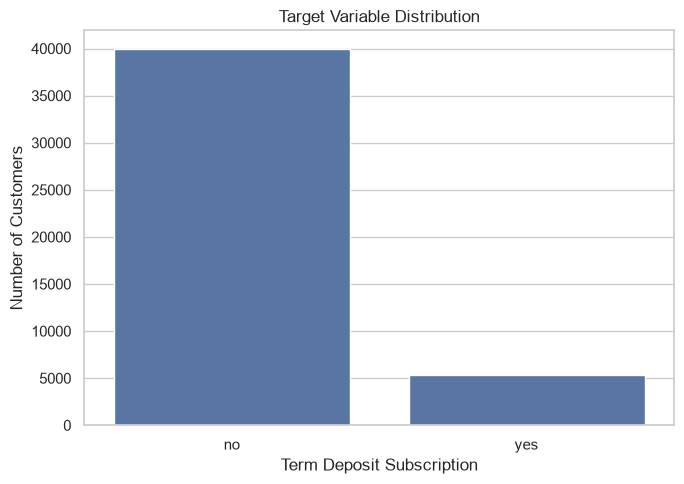

In [8]:
# ------------------------------------------------------------
# 1. Target Variable Distribution
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="y")

plt.title("Target Variable Distribution")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

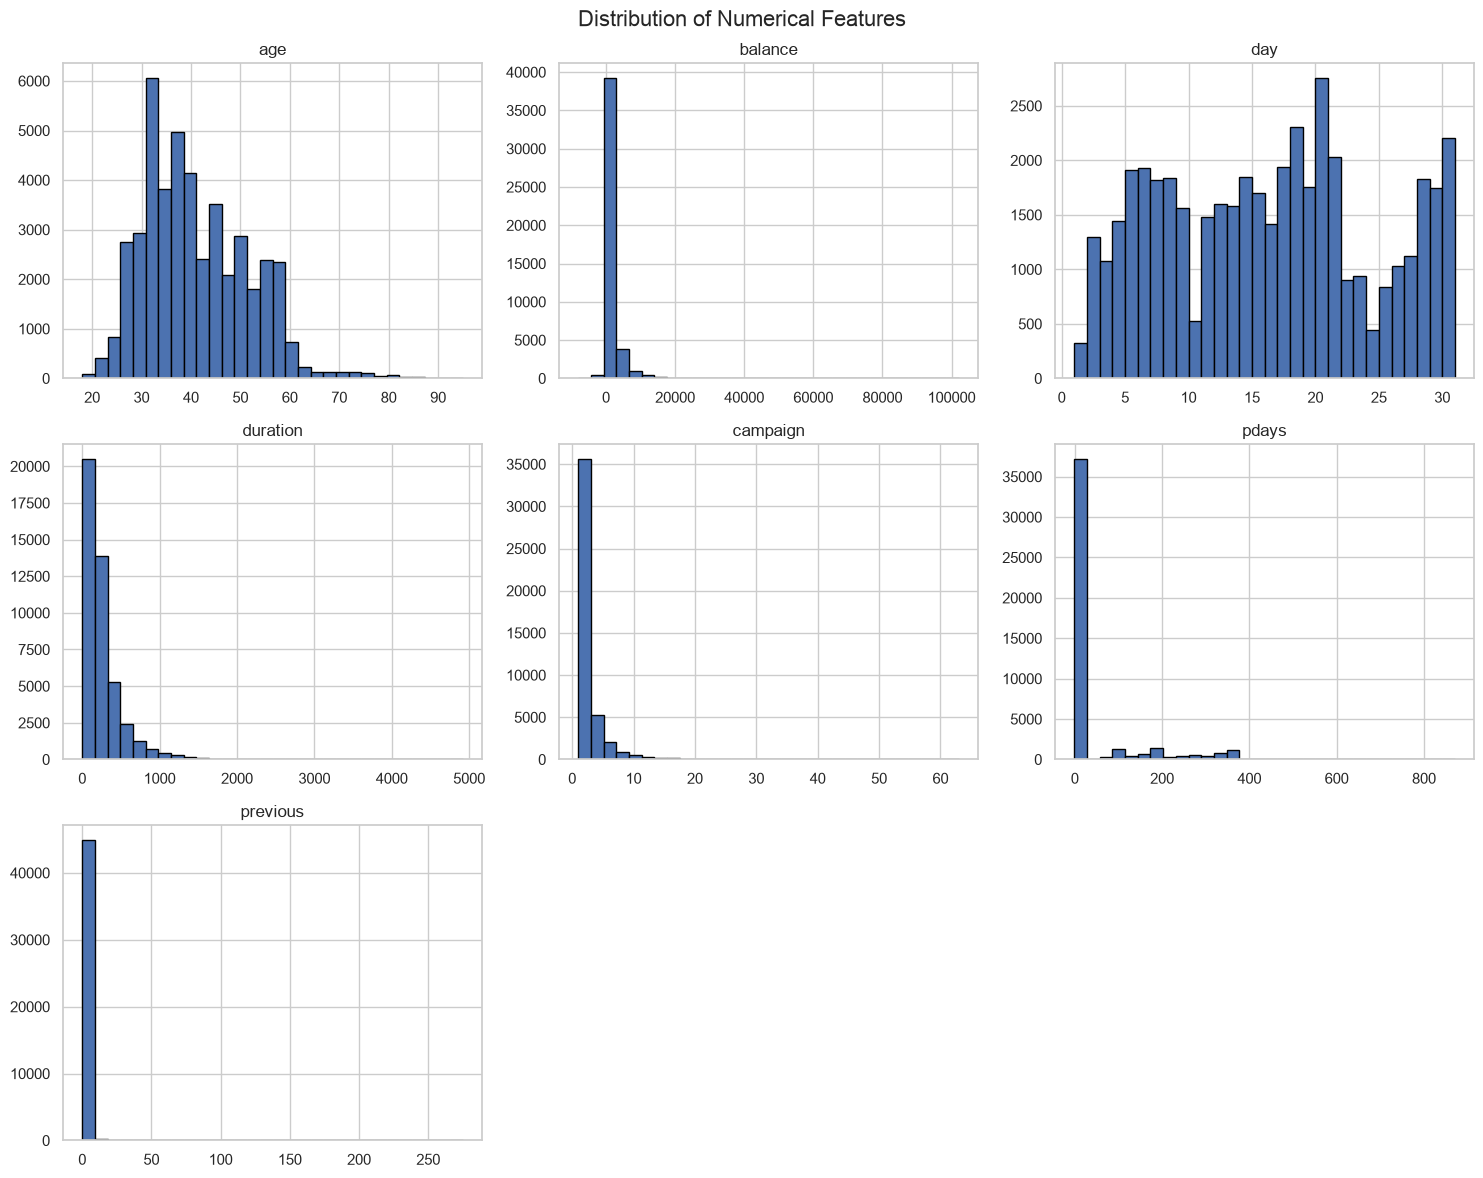

In [9]:
# ------------------------------------------------------------
# 2. Numerical Feature Distribution
# ------------------------------------------------------------

df[numerical_columns].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

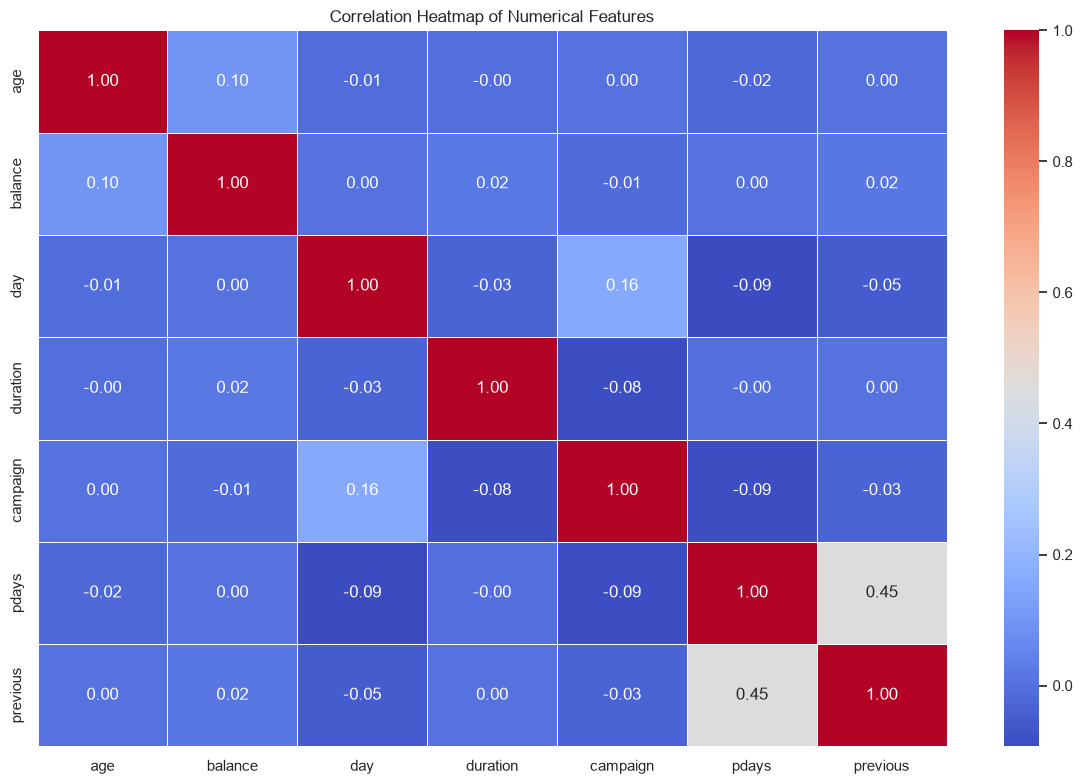

In [10]:
# ------------------------------------------------------------
# 3. Correlation Heatmap
# ------------------------------------------------------------

plt.figure(figsize=(12, 8))

correlation_matrix = df[numerical_columns].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

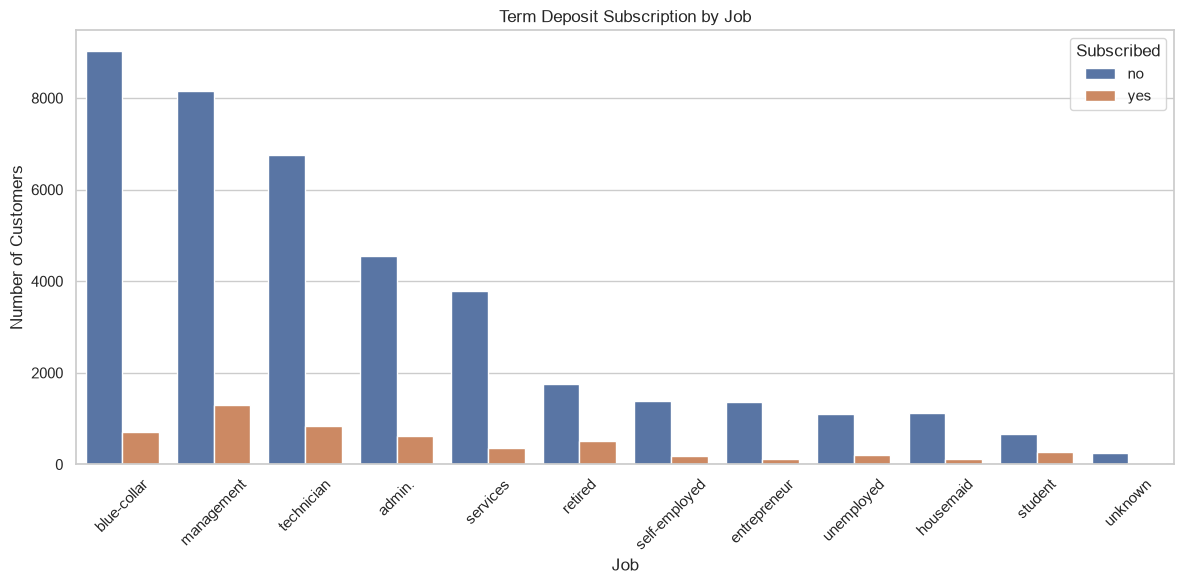

In [11]:
# ------------------------------------------------------------
# 4. Subscription Distribution by Job
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="job",
    hue="y",
    order=df["job"].value_counts().index
)

plt.title("Term Deposit Subscription by Job")
plt.xlabel("Job")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.legend(title="Subscribed")

plt.tight_layout()
plt.show()

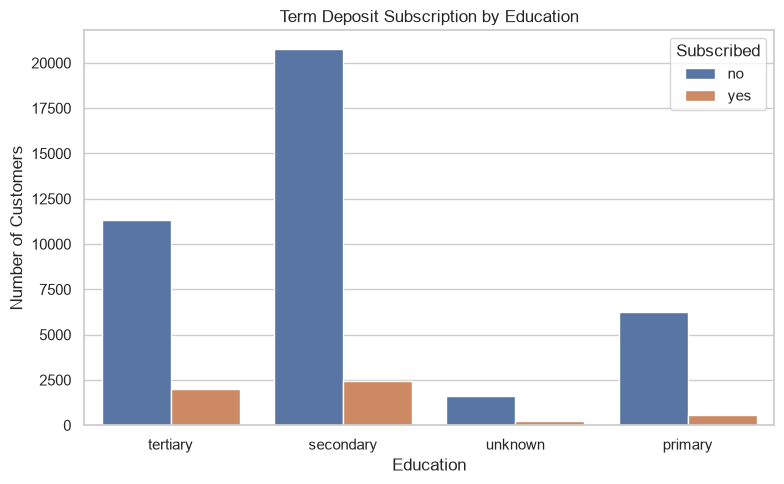

In [12]:
# ------------------------------------------------------------
# 5. Subscription Distribution by Education
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="education",
    hue="y"
)

plt.title("Term Deposit Subscription by Education")
plt.xlabel("Education")
plt.ylabel("Number of Customers")
plt.legend(title="Subscribed")

plt.tight_layout()
plt.show()

In [13]:
# ------------------------------------------------------------
# 6. Numerical Features Summary
# ------------------------------------------------------------

print("Numerical Features:")
print(numerical_columns)

print("\nCategorical Features:")
print(categorical_columns)

print("\nEDA completed successfully!")

Numerical Features:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

EDA completed successfully!


In [14]:
# ============================================================
# 3. Data Preprocessing
# ============================================================

import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer

# ------------------------------------------------------------
# 1. Remove Duration Column
# ------------------------------------------------------------

df_model = df.drop(columns=["duration"]).copy()

print("Duration column removed successfully!")

# ------------------------------------------------------------
# 2. Separate Input Features and Target Variable
# ------------------------------------------------------------

X = df_model.drop(columns=["y"])
y = df_model["y"]

print("\nInput Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

# ------------------------------------------------------------
# 3. Encode Target Variable
# ------------------------------------------------------------

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

print("\nTarget Classes:")
print(dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

# ------------------------------------------------------------
# 4. Identify Numerical and Categorical Features
# ------------------------------------------------------------

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("\nNumerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

# ------------------------------------------------------------
# 5. Create Preprocessing Pipeline
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    sparse_threshold=0
)

# ------------------------------------------------------------
# 6. Split Dataset into Training and Testing Sets
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# ------------------------------------------------------------
# 7. Apply Preprocessing
# ------------------------------------------------------------

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("\nProcessed Training Data Shape:", X_train_processed.shape)
print("Processed Testing Data Shape:", X_test_processed.shape)

print("\nData preprocessing completed successfully!")

Duration column removed successfully!

Input Features Shape: (45211, 15)
Target Variable Shape: (45211,)

Target Classes:
{'no': np.int64(0), 'yes': np.int64(1)}

Numerical Features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical Features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Training Data Shape: (36168, 15)
Testing Data Shape: (9043, 15)

Processed Training Data Shape: (36168, 50)
Processed Testing Data Shape: (9043, 50)

Data preprocessing completed successfully!


In [15]:
# ============================================================
# 4. Classification Model Implementation
# ============================================================

import time

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Initialize five classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    )
}

print("Five classification models initialized successfully!")

print("\nModels to be trained:")
for model_name in models:
    print("-", model_name)

Five classification models initialized successfully!

Models to be trained:
- Logistic Regression
- Decision Tree
- K-Nearest Neighbors
- Gaussian Naive Bayes
- Support Vector Machine


In [16]:
# ============================================================
# 5. Model Training
# ============================================================

trained_models = {}
training_times = {}

for model_name, model in models.items():

    print(f"\nTraining {model_name}...")

    start_time = time.time()

    model.fit(X_train_processed, y_train)

    end_time = time.time()

    training_times[model_name] = end_time - start_time
    trained_models[model_name] = model

    print(f"{model_name} trained successfully!")
    print(f"Training Time: {training_times[model_name]:.2f} seconds")

print("\nAll five classification models trained successfully!")


Training Logistic Regression...
Logistic Regression trained successfully!
Training Time: 0.12 seconds

Training Decision Tree...
Decision Tree trained successfully!
Training Time: 0.31 seconds

Training K-Nearest Neighbors...
K-Nearest Neighbors trained successfully!
Training Time: 0.00 seconds

Training Gaussian Naive Bayes...
Gaussian Naive Bayes trained successfully!
Training Time: 0.01 seconds

Training Support Vector Machine...
Support Vector Machine trained successfully!
Training Time: 212.69 seconds

All five classification models trained successfully!


In [17]:
# ============================================================
# 6. Model Evaluation
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

import pandas as pd

# Store evaluation results
evaluation_results = []

# Evaluate each trained model
for model_name, model in trained_models.items():

    # Predict test data
    y_pred = model.predict(X_test_processed)

    # Predict probabilities for AUC
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(y_test, y_prob)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    # Store results
    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "AUC Score": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

# Create comparison DataFrame
results_df = pd.DataFrame(evaluation_results)

# Display results
print("Classification Model Evaluation Results:\n")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "AUC Score": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "MCC": "{:.4f}"
    })
)

Classification Model Evaluation Results:



,Model,Accuracy,AUC Score,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8933,0.7717,0.6632,0.1786,0.2815,0.3065
1,Decision Tree,0.8308,0.6094,0.2948,0.3204,0.3071,0.2111
2,K-Nearest Neighbors,0.8874,0.7027,0.5529,0.1975,0.2911,0.2833
3,Gaussian Naive Bayes,0.8452,0.7514,0.3708,0.4641,0.4123,0.3271
4,Support Vector Machine,0.8933,0.7183,0.6555,0.1853,0.2889,0.3098


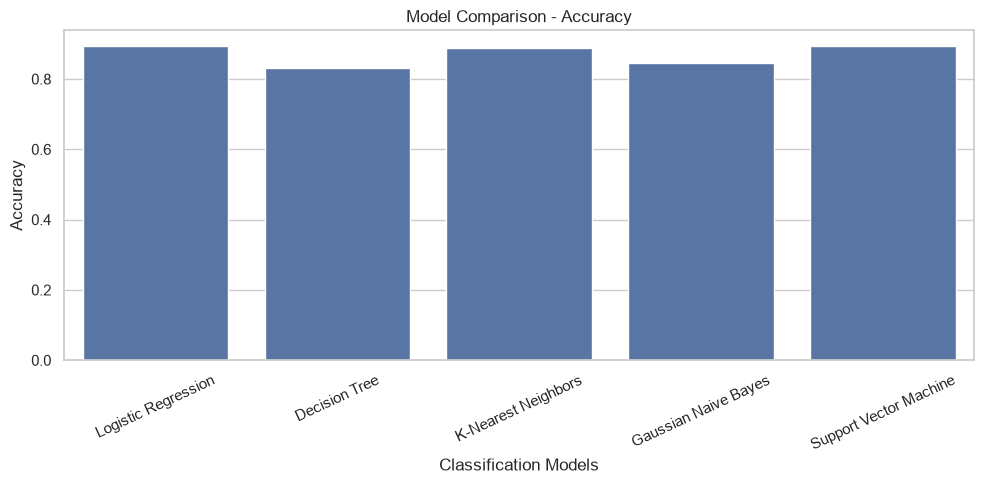

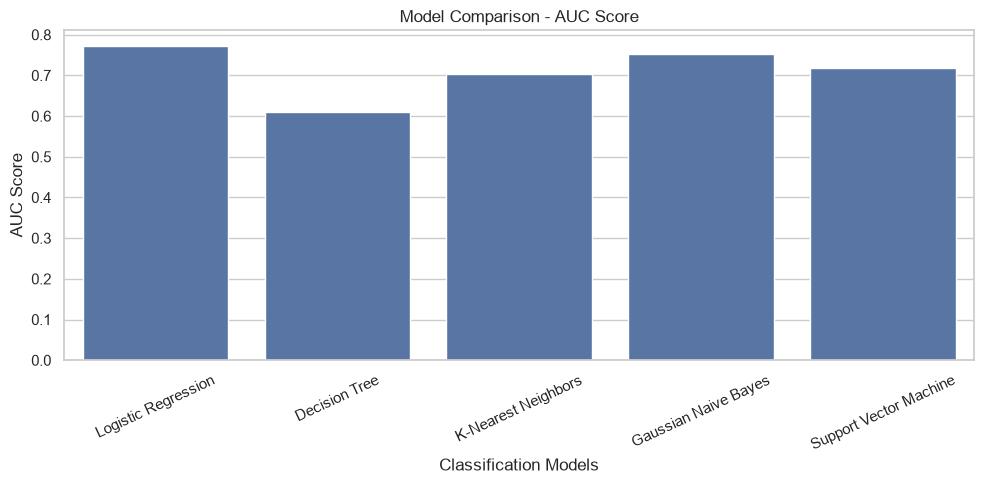

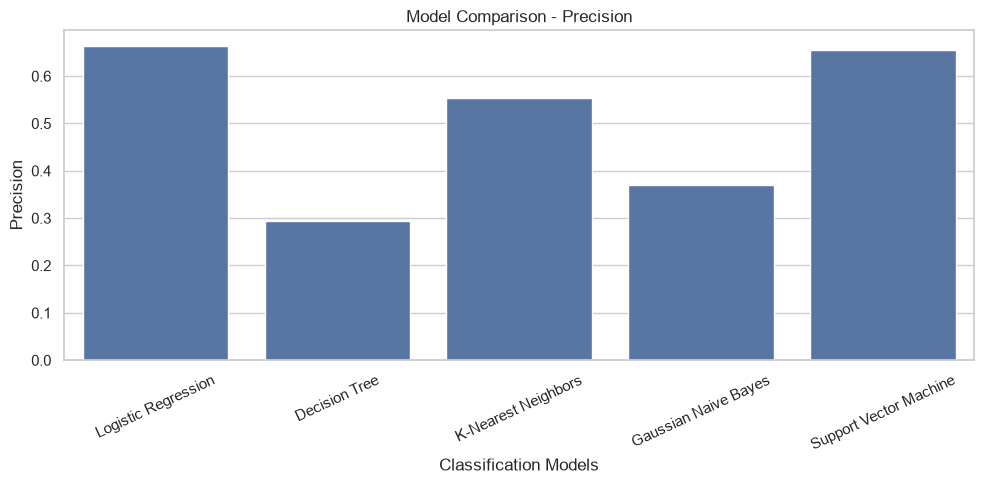

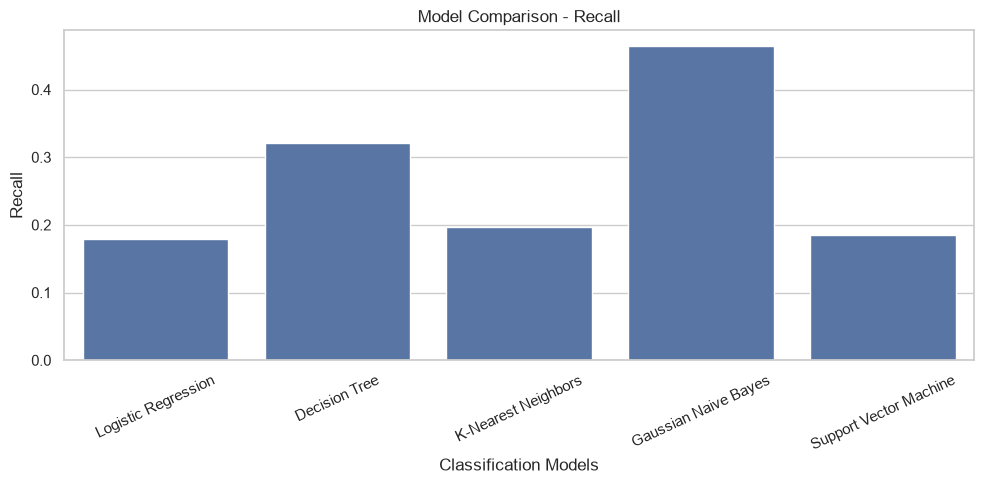

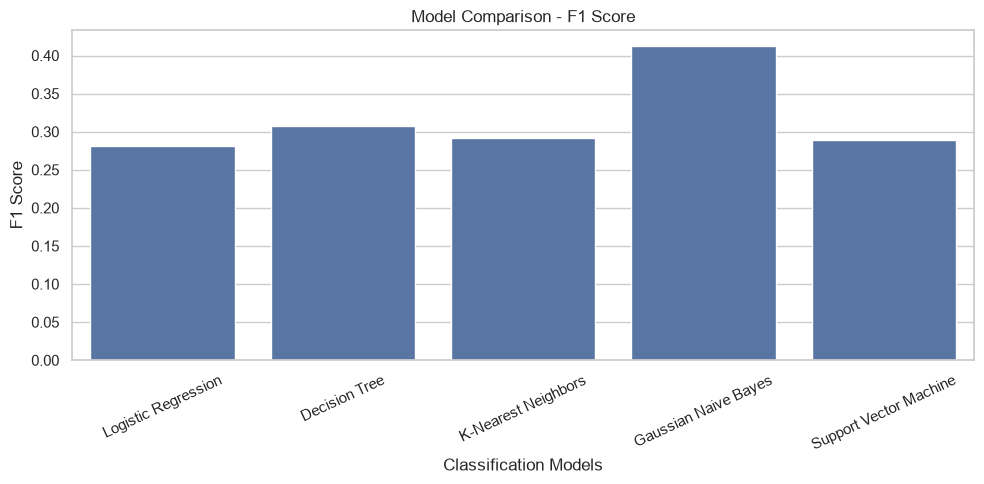

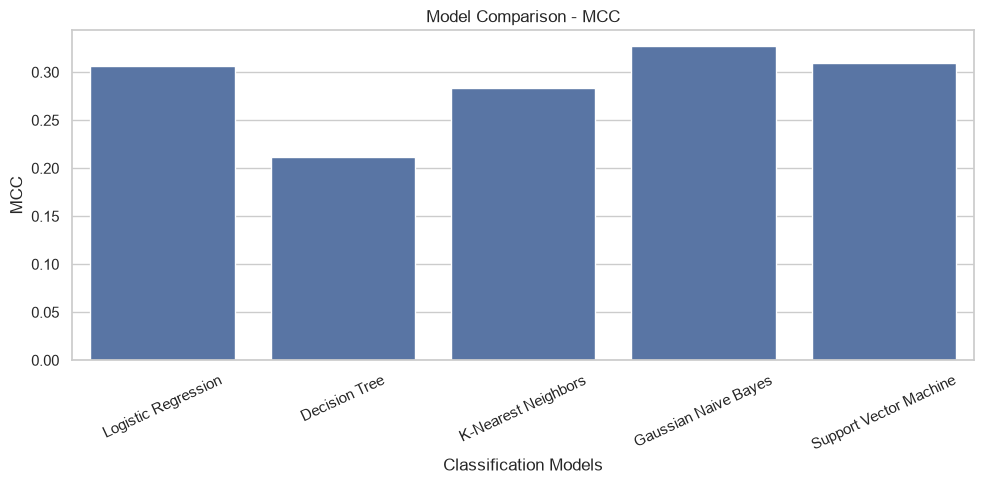

In [18]:
# ============================================================
# 7. Classification Model Performance Comparison
# ============================================================

metrics = [
    "Accuracy",
    "AUC Score",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Classification Models")
    plt.ylabel(metric)
    plt.xticks(rotation=25)

    plt.tight_layout()
    plt.show()

The performance of five classification algorithms was compared using Accuracy, AUC Score, Precision, Recall, F1 Score, and Matthews Correlation Coefficient. Logistic Regression achieved the highest AUC score of 0.7717 and precision of 0.6632, while Logistic Regression and Support Vector Machine achieved the highest accuracy of 0.8933. Gaussian Naive Bayes achieved the highest recall of 0.4641, F1 Score of 0.4123, and MCC of 0.3271. Considering the imbalanced nature of the dataset, Gaussian Naive Bayes was selected as the overall best-performing model based on its balanced classification performance.


Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.99      0.94      7985
         Yes       0.66      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.87      9043



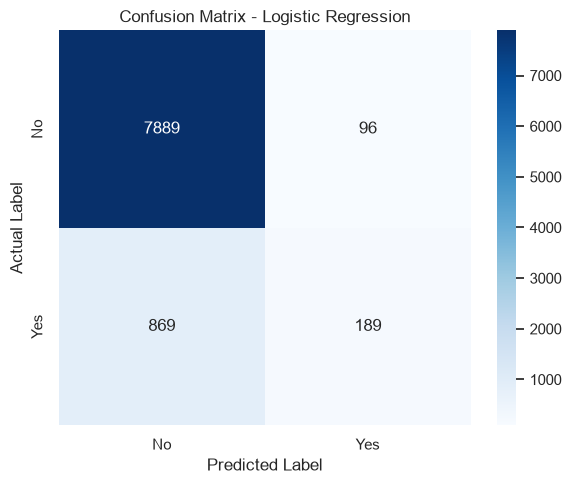


Model: Decision Tree

Classification Report:
              precision    recall  f1-score   support

          No       0.91      0.90      0.90      7985
         Yes       0.29      0.32      0.31      1058

    accuracy                           0.83      9043
   macro avg       0.60      0.61      0.61      9043
weighted avg       0.84      0.83      0.83      9043



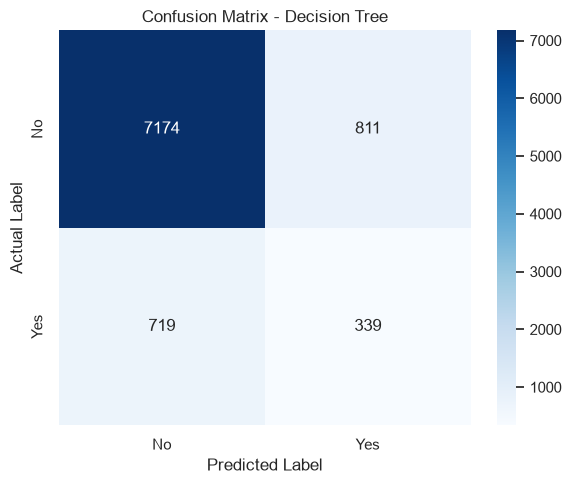


Model: K-Nearest Neighbors

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.98      0.94      7985
         Yes       0.55      0.20      0.29      1058

    accuracy                           0.89      9043
   macro avg       0.73      0.59      0.61      9043
weighted avg       0.86      0.89      0.86      9043



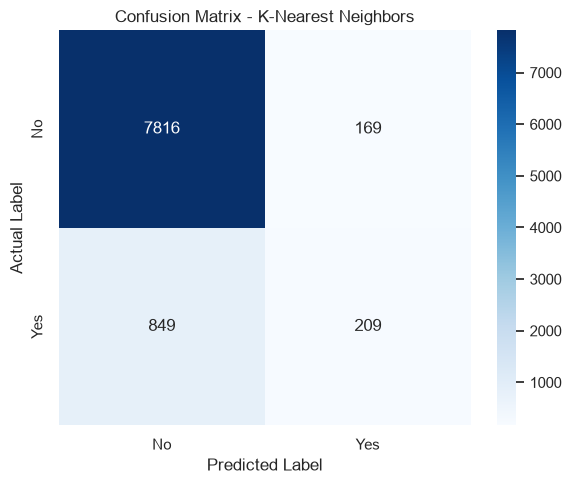


Model: Gaussian Naive Bayes

Classification Report:
              precision    recall  f1-score   support

          No       0.93      0.90      0.91      7985
         Yes       0.37      0.46      0.41      1058

    accuracy                           0.85      9043
   macro avg       0.65      0.68      0.66      9043
weighted avg       0.86      0.85      0.85      9043



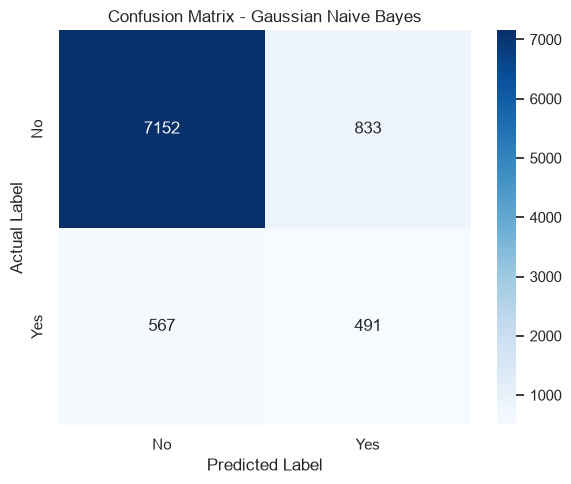


Model: Support Vector Machine

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.99      0.94      7985
         Yes       0.66      0.19      0.29      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.59      0.62      9043
weighted avg       0.87      0.89      0.87      9043



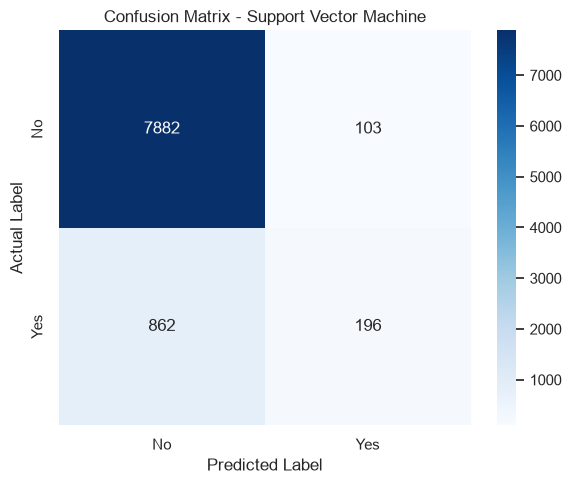


Confusion matrix evaluation completed!


In [19]:
# ============================================================
# 8. Confusion Matrix and Classification Report
# ============================================================

from sklearn.metrics import confusion_matrix, classification_report

import matplotlib.pyplot as plt
import seaborn as sns

for model_name, model in trained_models.items():

    print("\n" + "=" * 60)
    print(f"Model: {model_name}")
    print("=" * 60)

    # Predict test data
    y_pred = model.predict(X_test_processed)

    # Classification report
    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["No", "Yes"],
            zero_division=0
        )
    )

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

print("\nConfusion matrix evaluation completed!")

In [20]:
# ============================================================
# 9. Save Trained Models and Preprocessing Artifacts
# ============================================================

import joblib
import json

# ------------------------------------------------------------
# 1. Save All Five Trained Models
# ------------------------------------------------------------

model_files = {
    "Logistic Regression": "logistic_regression.pkl",
    "Decision Tree": "decision_tree.pkl",
    "K-Nearest Neighbors": "knn.pkl",
    "Gaussian Naive Bayes": "gaussian_naive_bayes.pkl",
    "Support Vector Machine": "svm.pkl"
}

for model_name, model in trained_models.items():

    file_name = model_files[model_name]

    joblib.dump(
        model,
        MODEL_DIR / file_name
    )

    print(f"{model_name} saved successfully!")

# ------------------------------------------------------------
# 2. Save Preprocessing Artifacts
# ------------------------------------------------------------

joblib.dump(
    preprocessor,
    MODEL_DIR / "preprocessor.pkl"
)

joblib.dump(
    label_encoder,
    MODEL_DIR / "label_encoder.pkl"
)

print("\nPreprocessor saved successfully!")
print("Label encoder saved successfully!")

# ------------------------------------------------------------
# 3. Save Model Evaluation Results
# ------------------------------------------------------------

results_df.to_csv(
    OUTPUT_DIR / "model_evaluation_results.csv",
    index=False
)

print("\nModel evaluation results saved successfully!")

# ------------------------------------------------------------
# 4. Save Test Dataset for Streamlit Application
# ------------------------------------------------------------

test_data = X_test.reset_index(drop=True).copy()

test_data["y"] = label_encoder.inverse_transform(y_test)

test_data.to_csv(
    BASE_DIR / "test_data.csv",
    index=False
)

print("\nTest dataset saved successfully!")

# ------------------------------------------------------------
# 5. Save Feature Information
# ------------------------------------------------------------

feature_information = {
    "numerical_features": numerical_features,
    "categorical_features": categorical_features,
    "input_features": X.columns.tolist(),
    "target_column": "y",
    "target_classes": label_encoder.classes_.tolist()
}

with open(MODEL_DIR / "feature_information.json", "w") as file:
    json.dump(feature_information, file, indent=4)

print("Feature information saved successfully!")

# ------------------------------------------------------------
# 6. Display Saved Files
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("SAVED PROJECT FILES")
print("=" * 55)

for folder in [MODEL_DIR, OUTPUT_DIR]:
    print(f"\n{folder.name}/")

    for file in sorted(folder.iterdir()):
        print("  ", file.name)

print("\nRoot directory:")
print("  test_data.csv")

print("\nAll models and artifacts saved successfully!")

Logistic Regression saved successfully!
Decision Tree saved successfully!
K-Nearest Neighbors saved successfully!
Gaussian Naive Bayes saved successfully!
Support Vector Machine saved successfully!

Preprocessor saved successfully!
Label encoder saved successfully!

Model evaluation results saved successfully!

Test dataset saved successfully!
Feature information saved successfully!

SAVED PROJECT FILES

models/
   decision_tree.pkl
   feature_information.json
   gaussian_naive_bayes.pkl
   knn.pkl
   label_encoder.pkl
   logistic_regression.pkl
   preprocessor.pkl
   svm.pkl

outputs/
   model_evaluation_results.csv

Root directory:
  test_data.csv

All models and artifacts saved successfully!
